# Demand forecasting: daily bike-sharing rentals
Daily rentals (Capital Bikeshare, Washington DC, 2011-2012) with calendar and weather data. Models are trained on the first 18 months and tested **out-of-sample** on the final 6 months against seasonal-naive baselines, the same discipline used for sales or cash-flow forecasting.

731 days, mean 4,504 rentals/day


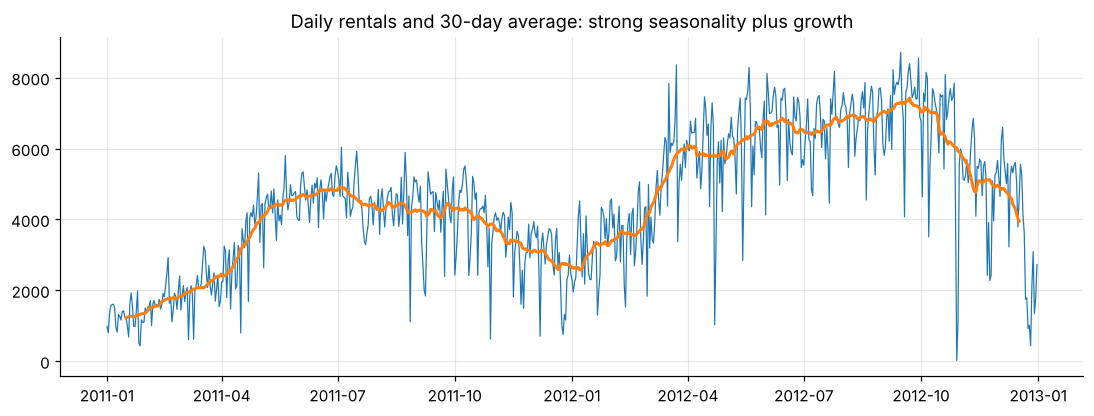

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
d = pd.read_csv("data/bike_sharing_daily.csv", parse_dates=["dteday"]).set_index("dteday")
print(f"{len(d)} days, mean {d.cnt.mean():,.0f} rentals/day")
fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(d.cnt, lw=0.8); ax.plot(d.cnt.rolling(30, center=True).mean(), lw=2)
ax.set_title("Daily rentals and 30-day average: strong seasonality plus growth"); plt.savefig(IMG / "demand.png", bbox_inches="tight"); plt.show()

In [2]:
f = pd.DataFrame(index=d.index)
f["trend"] = np.arange(len(d)); f["doy_sin"] = np.sin(2 * np.pi * d.index.dayofyear / 365.25); f["doy_cos"] = np.cos(2 * np.pi * d.index.dayofyear / 365.25)
f = f.join(pd.get_dummies(d.weekday, prefix="wd", dtype=float)).join(pd.get_dummies(d.weathersit, prefix="weather", dtype=float))
f[["holiday", "workingday", "temp", "atemp", "hum", "windspeed"]] = d[["holiday", "workingday", "temp", "atemp", "hum", "windspeed"]]
f["temp2"] = f.temp ** 2
split = "2012-07-01"
Xtr, Xte, ytr, yte = f.loc[:split].iloc[:-1], f.loc[split:], d.cnt.loc[:split].iloc[:-1], d.cnt.loc[split:]
preds = {
    "Naive: same weekday last week": d.cnt.shift(7).loc[split:],
    "Naive: same day last year x growth": (d.cnt.shift(364) * (ytr.iloc[-90:].mean() / d.cnt.shift(364).loc[ytr.index[-90:]].mean())).loc[split:],
    "Ridge (calendar + weather)": pd.Series(RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(Xtr, ytr).predict(Xte), index=yte.index),
    "Gradient boosting": pd.Series(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(Xtr, ytr).predict(Xte), index=yte.index),
}
# WAPE (sum of absolute errors / sum of actuals) instead of MAPE, which explodes on near-zero days such as Hurricane Sandy
res = pd.DataFrame({k: {"MAE (rentals/day)": mean_absolute_error(yte, p), "WAPE": np.abs(yte - p).sum() / yte.sum() * 100} for k, p in preds.items()}).T
res["improvement vs weekly naive"] = 1 - res["MAE (rentals/day)"] / res.loc["Naive: same weekday last week", "MAE (rentals/day)"]
res.style.format({"MAE (rentals/day)": "{:,.0f}", "WAPE": "{:.1f}%", "improvement vs weekly naive": "{:+.0%}"})

,MAE (rentals/day),WAPE,improvement vs weekly naive
Naive: same weekday last week,"1,130",18.7%,+0%
Naive: same day last year x growth,"1,168",19.3%,-3%
Ridge (calendar + weather),878,14.5%,+22%
Gradient boosting,900,14.9%,+20%


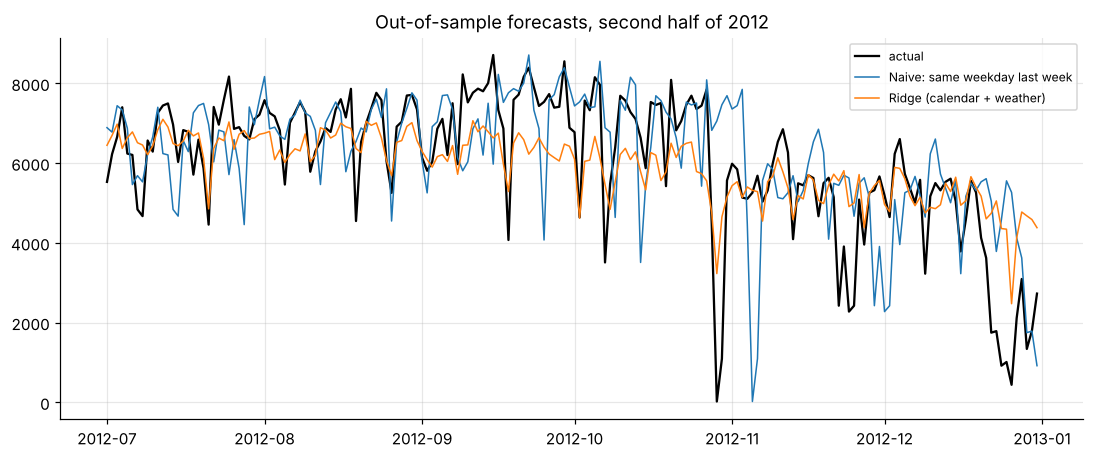

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(yte, color="k", lw=1.5, label="actual")
for k in ["Naive: same weekday last week", "Ridge (calendar + weather)"]: ax.plot(preds[k], lw=1, label=k)
ax.set_title("Out-of-sample forecasts, second half of 2012"); ax.legend(fontsize=8); plt.savefig(IMG / "forecast.png", bbox_inches="tight"); plt.show()

**Takeaways:** a weekly-lag naive forecast is a tough benchmark, and beating it requires *explanatory* inputs. A transparent ridge model on the trend, seasonality, calendar and weather cuts the error by about a fifth versus the naive forecast. It slightly beats gradient boosting, because tree ensembles cannot extrapolate a growth trend beyond the training range, a classic pitfall when forecasting growing businesses. WAPE is reported instead of MAPE because percentage errors explode on near-zero days. Note that the October 2012 trough is Hurricane Sandy, a shock no historical model anticipates.